# Stage 2 & 3: Data Understanding, Quality Audit, and Data Cleaning
**Dataset:** Craigslist Used Cars & Trucks Dataset (`vehicles.csv`)  
**Source & License:** Kaggle (`austinreese/craigslist-carstrucks-data`) — CC0 1.0 Public Domain  
**Objective:** Inspect raw dataset structure (295,451 rows × 41 columns), identify data quality issues, regional/temporal bias, and execute a reproducible cleaning pipeline for used vehicle price prediction.

Cell 1: Mount Drive & Load Cleaned Dataset

In [1]:
# ==========================================
# CELL 1: Setup & Load vehicles_cleaned.csv
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Google Drive mount karein
drive.mount('/content/drive')

# Apna cleaned dataset load karein (agar path different ho toh adjust kar lein)
file_path = '/content/drive/MyDrive/vehicles_cleaned.csv'
df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Mounted at /content/drive
Dataset Loaded Successfully!
Shape: 191,840 rows x 23 columns


,region,price,year,manufacturer,model,condition,fuel,odometer,title_status,transmission,...,state,lat,long,posting_date,seller_type,image_count,delivery_available,odometer_broken,odometer_rolled_over,cylinders_num
0,sf bay area,27999.0,2022,ford,explorer st,excellent,gas,99179.0,clean,automatic,...,ca,37.371435,-122.047863,2026-11-03 03:24:16+00:00,dealer,20,0,0,0,6.0
1,sf bay area,15999.0,2016,rover,sport,excellent,gas,82896.0,clean,automatic,...,ca,37.371435,-122.047863,2026-11-03 03:22:44+00:00,dealer,20,0,0,0,6.0
2,sf bay area,18999.0,2009,dodge,challenger lc srt8,excellent,gas,81724.0,clean,automatic,...,ca,37.371435,-122.047863,2026-11-03 03:21:10+00:00,dealer,20,0,0,0,8.0
3,sf bay area,27999.0,2020,ford,expedition max platinum,excellent,gas,96104.0,clean,automatic,...,ca,37.371435,-122.047863,2026-11-03 03:19:32+00:00,dealer,20,0,0,0,6.0
4,sf bay area,29999.0,2023,ford,explorer st-line,excellent,gas,54131.0,clean,automatic,...,ca,37.371435,-122.047863,2026-11-03 03:17:47+00:00,dealer,20,0,0,0,4.0


Cell 2: Summary Statistics & Target Variable (price) Distribution

               price           year       odometer  cylinders_num  \
count  191840.000000  191840.000000  190204.000000  140197.000000   
mean    16659.059920    2013.624692  115807.536797       5.716378   
std     15800.102267       7.718304   62257.543660       1.617363   
min       500.000000    1980.000000       1.000000       3.000000   
25%      6495.000000    2010.000000   73450.250000       4.000000   
50%     11995.000000    2015.000000  112946.000000       6.000000   
75%     21195.000000    2019.000000  152324.000000       6.000000   
max    150000.000000    2026.000000  500000.000000      12.000000   

         image_count  
count  191840.000000  
mean       16.398144  
std         7.061394  
min         0.000000  
25%        11.000000  
50%        18.000000  
75%        24.000000  
max        24.000000  


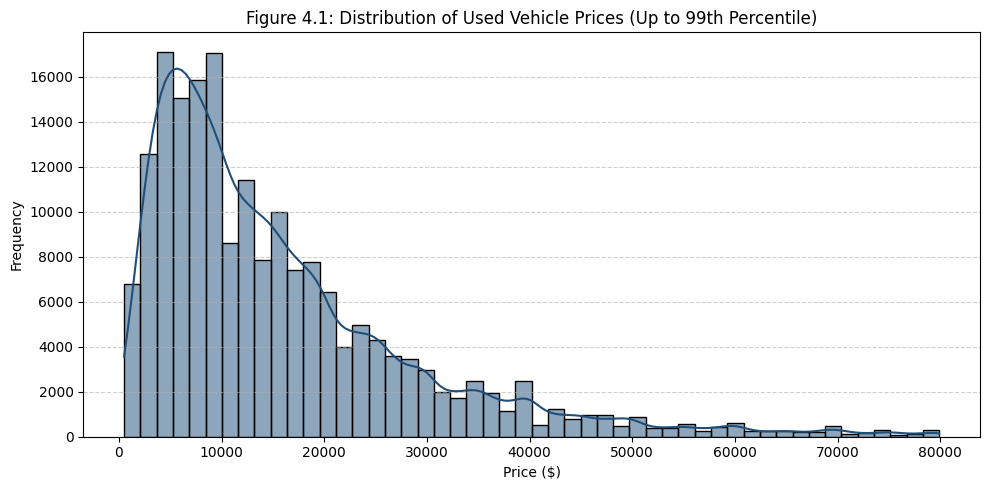

Saved: fig_4_1_price_distribution.png


In [2]:
# ==========================================
# CELL 2: Figure 4.1 - Price Distribution
# ==========================================
print(df[['price', 'year', 'odometer', 'cylinders_num', 'image_count']].describe())

plt.figure(figsize=(10, 5))
# Extreme outliers ko visual clarity ke liye 99th percentile tak filter kar ke plot karein
price_cap = df['price'].quantile(0.99)
sns.histplot(df[df['price'] <= price_cap]['price'], bins=50, kde=True, color='#1F4E79')
plt.title('Figure 4.1: Distribution of Used Vehicle Prices (Up to 99th Percentile)')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('fig_4_1_price_distribution.png', dpi=300)
plt.show()
print("Saved: fig_4_1_price_distribution.png")

Cell 3: Categorical & Market Insights (Top Manufacturers, Fuel, Condition, Seller Type)

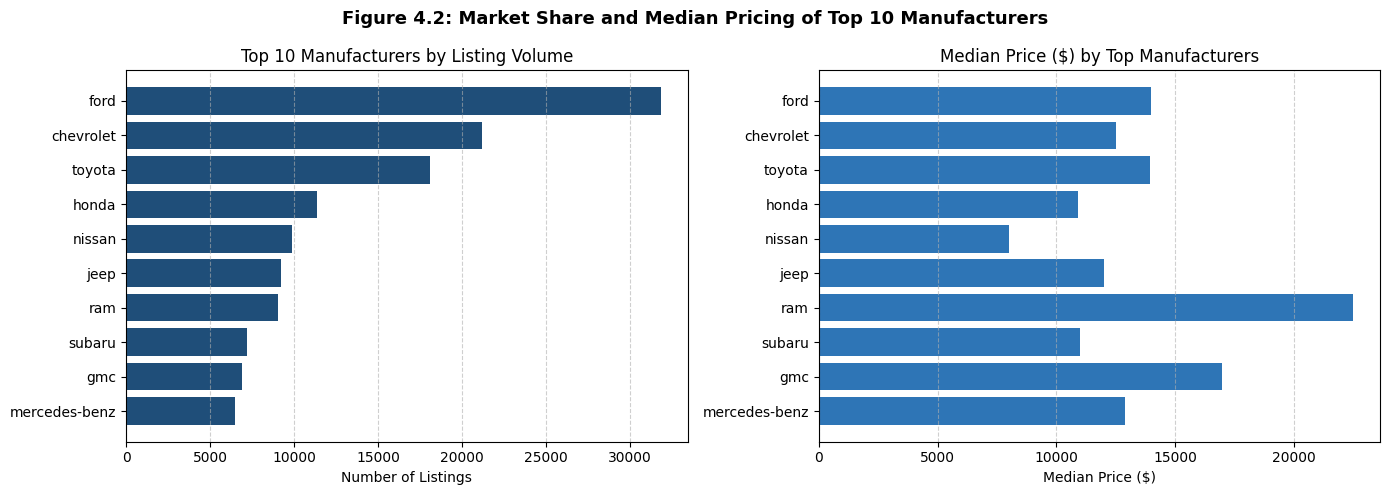

Saved: fig_4_2_top_manufacturers.png


In [3]:
# ==========================================
# CELL 3: Figure 4.2 - Top 10 Manufacturers & Median Price
# ==========================================
top_brands = df['manufacturer'].value_counts().head(10).index
brand_summary = (
    df[df['manufacturer'].isin(top_brands)]
    .groupby('manufacturer')['price']
    .agg(['count', 'median'])
    .sort_values(by='count', ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Listing Count
axes[0].barh(brand_summary.index, brand_summary['count'], color='#1F4E79')
axes[0].set_title('Top 10 Manufacturers by Listing Volume')
axes[0].set_xlabel('Number of Listings')
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

# Median Price
axes[1].barh(brand_summary.index, brand_summary['median'], color='#2E75B6')
axes[1].set_title('Median Price ($) by Top Manufacturers')
axes[1].set_xlabel('Median Price ($)')
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.suptitle('Figure 4.2: Market Share and Median Pricing of Top 10 Manufacturers', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_4_2_top_manufacturers.png', dpi=300)
plt.show()
print("Saved: fig_4_2_top_manufacturers.png")

Cell 4: Depreciation Analysis (Vehicle Age vs. Price & Odometer)

/tmp/ipykernel_863/2379836697.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


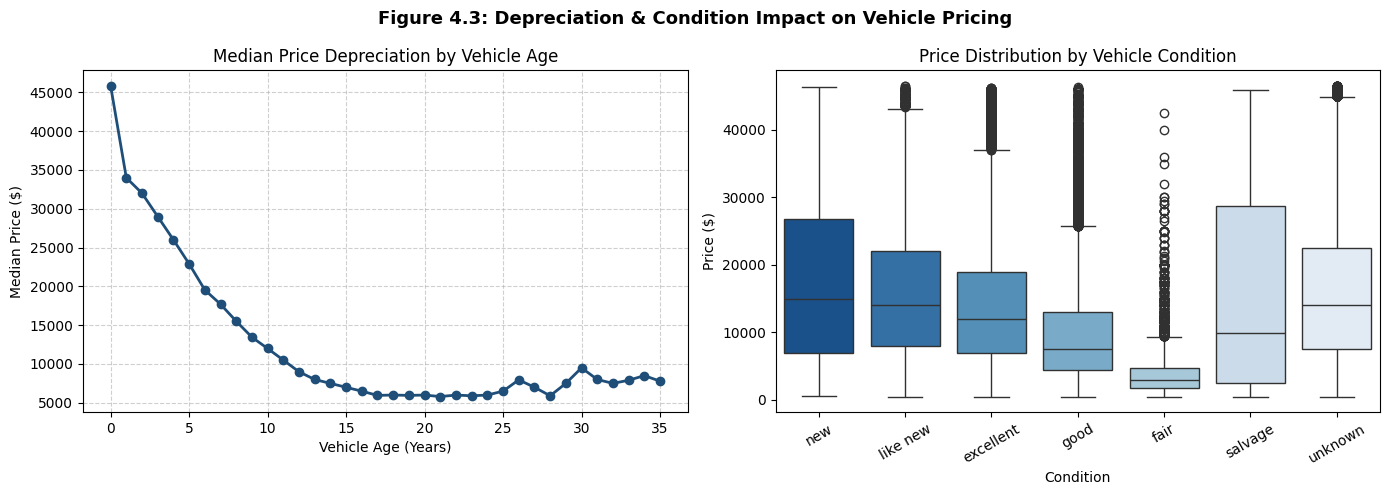

Saved: fig_4_3_depreciation_condition.png


In [4]:
# ==========================================
# CELL 4: Figure 4.3 - Vehicle Age & Condition vs Price
# ==========================================
# Feature Engineering: Vehicle Age
df['vehicle_age'] = 2026 - df['year']
df_valid_age = df[(df['vehicle_age'] >= 0) & (df['vehicle_age'] <= 35)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age vs Median Price trend
age_price = df_valid_age.groupby('vehicle_age')['price'].median()
axes[0].plot(age_price.index, age_price.values, marker='o', color='#1F4E79', linewidth=2)
axes[0].set_title('Median Price Depreciation by Vehicle Age')
axes[0].set_xlabel('Vehicle Age (Years)')
axes[0].set_ylabel('Median Price ($)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Condition vs Price Boxplot (capped at 95th percentile for clean view)
cond_order = ['new', 'like new', 'excellent', 'good', 'fair', 'salvage', 'unknown']
existing_conds = [c for c in cond_order if c in df['condition'].unique()]
sns.boxplot(
    data=df[df['price'] <= df['price'].quantile(0.95)],
    x='condition',
    y='price',
    order=existing_conds,
    palette='Blues_r',
    ax=axes[1]
)
axes[1].set_title('Price Distribution by Vehicle Condition')
axes[1].set_xlabel('Condition')
axes[1].set_ylabel('Price ($)')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Figure 4.3: Depreciation & Condition Impact on Vehicle Pricing', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_4_3_depreciation_condition.png', dpi=300)
plt.show()
print("Saved: fig_4_3_depreciation_condition.png")

Cell 5: Correlation Matrix (Numerical Features)

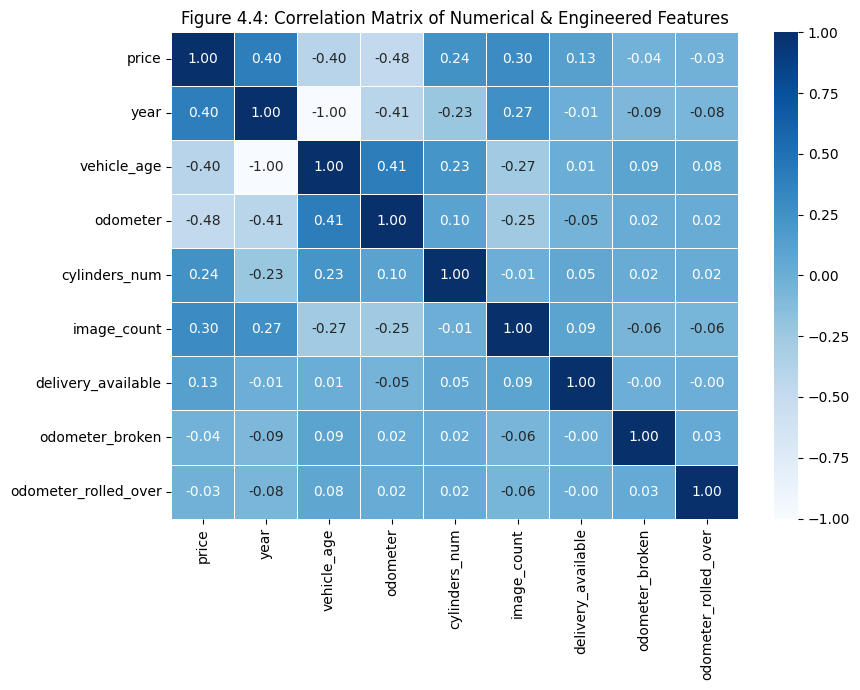

Saved: fig_4_4_correlation_heatmap.png


In [5]:
# ==========================================
# CELL 5: Figure 4.4 - Correlation Heatmap
# ==========================================
num_cols = [
    'price', 'year', 'vehicle_age', 'odometer', 'cylinders_num',
    'image_count', 'delivery_available', 'odometer_broken', 'odometer_rolled_over'
]
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Figure 4.4: Correlation Matrix of Numerical & Engineered Features')
plt.tight_layout()
plt.savefig('fig_4_4_correlation_heatmap.png', dpi=300)
plt.show()
print("Saved: fig_4_4_correlation_heatmap.png")

Cell 6: Feature Engineering & Baseline Price Prediction Model (Random Forest)

=== Baseline Random Forest Model Performance ===
R² Score : 0.8144
MAE      : $3,907.96
RMSE     : $6,807.55


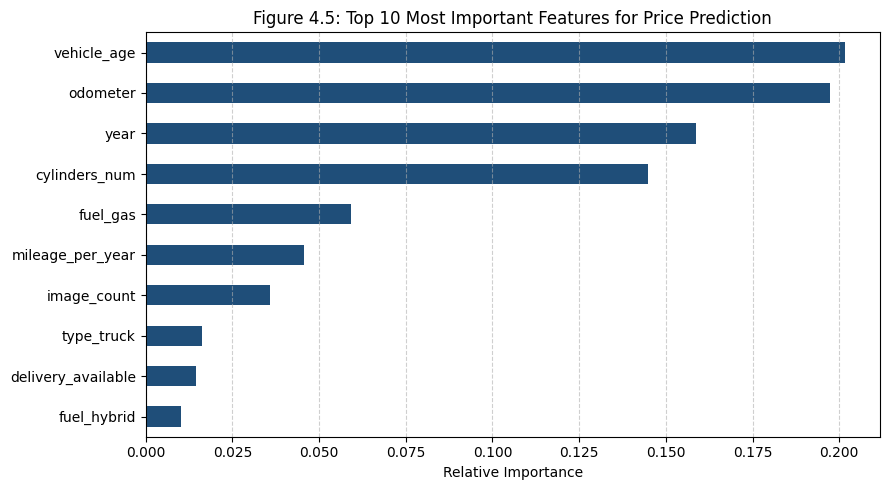

Saved: fig_4_5_feature_importance.png


In [6]:
# ==========================================
# CELL 6: Feature Engineering & Baseline Model
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Modeling ke liye clean subset tayyar karein
model_df = df.copy()
model_df['mileage_per_year'] = model_df['odometer'] / (model_df['vehicle_age'] + 1)

features = [
    'year', 'vehicle_age', 'odometer', 'mileage_per_year', 'cylinders_num',
    'image_count', 'delivery_available', 'condition', 'fuel',
    'title_status', 'transmission', 'drive', 'type', 'seller_type'
]

model_df = model_df[features + ['price']].dropna()
# Extreme price outliers remove karein taake model realistic evaluation de
model_df = model_df[(model_df['price'] >= 500) & (model_df['price'] <= 150000)]

# One-hot encoding for categorical features
X = pd.get_dummies(model_df[features], drop_first=True)
y = model_df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== Baseline Random Forest Model Performance ===")
print(f"R² Score : {r2:.4f}")
print(f"MAE      : ${mae:,.2f}")
print(f"RMSE     : ${rmse:,.2f}")

# Top 10 Feature Importances plot
feat_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)
plt.figure(figsize=(9, 5))
feat_imp.plot(kind='barh', color='#1F4E79')
plt.title('Figure 4.5: Top 10 Most Important Features for Price Prediction')
plt.xlabel('Relative Importance')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('fig_4_5_feature_importance.png', dpi=300)
plt.show()
print("Saved: fig_4_5_feature_importance.png")